# Predicting Hit Songs Using Audio Features

## Task - 1
### Context and Problem Statement

I'm a data scientist and working with Gbedu Music, a small independent music production company supporting emerging artists. While the company’s founder has strong musical intuition as an experienced DJ, decisions about which songs to promote are currently based mainly on subjective judgment.
Producing and promoting music is costly, and only a small fraction of songs become successful. To reduce this risk, Gbedu Music is interested in using data-driven analysis to support decisions before a song is released, when no performance history is available.
The problem addressed in this project is a binary classification task. Using only a song’s audio features (e.g. danceability, energy, loudness, valence), the goal is to predict whether a song will become a hit or a non-hit. The classification target is derived from the song’s popularity score.


To define the target, I convert Spotify’s popularity score into a binary label: songs with popularity above a chosen threshold are treated as hits, and the rest as non-hits.


The core research question is:
"Can a song’s success be predicted reliably using only its audio characteristics?"

### Value of Solving the Problem

If successful, the model enables:

* More efficient use of marketing resources

* Early decision support before release

* Scalable evaluation of large song catalogs

* Insights into audio characteristics linked to success

Overall, the model supports more objective and data-driven decision-making in music production.

### Quality Criteria for Model Evaluation

Two evaluation metrics are used throughout the project:

* ROC-AUC, to assess how well the model distinguishes between hit and non-hit songs under potential class imbalance.

* F1-score, to balance the trade-off between missing potential hits and falsely promoting unsuccessful songs.

## Import and Settings

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, ParameterGrid

pd.options.display.max_columns = None

# Settings for plots
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Task - 2
### Dataset Description

The dataset used in this project contains popular songs released between 2010 and 2019 and was originally sourced from Spotify, a major audio streaming platform, and is publicly available on Kaggle at the following link:
https://www.kaggle.com/datasets/leonardopena/top-spotify-songs-from-20102019-by-year

### Dataset Explanation

The dataset contains attributes of songs that appeared in the **Billboard Top 100** between **2010 and 2019**. The data was originally sourced from Spotify and includes both **descriptive metadata** and **numerical audio features** that characterize different musical properties of each song.

Each row represents a single song. The features describe rhythmic, acoustic, and perceptual aspects of music and are suitable for analyzing patterns related to song popularity. The popularity score is later used to derive the target variable for the classification task.

| Feature | Range / Values | Explanation |
|--------|----------------|-------------|
| `title` | Text | Title of the song |
| `artist` | Text | Name of the performing artist or band |
| `top genre` | Text | Main musical genre of the song |
| `year` | Integer (2010–2019) | Year of release |
| `bpm` | ℝ⁺ | Tempo of the song measured in beats per minute |
| `nrgy` | 0–100 | Energy level indicating intensity and activity |
| `dnce` | 0–100 | Danceability, describing how suitable the song is for dancing |
| `dB` | ℝ (typically negative) | Loudness of the song measured in decibels |
| `live` | 0–100 | Likelihood that the song was recorded live |
| `val` | 0–100 | Valence, representing the musical positivity or mood |
| `dur` | ℝ⁺ (seconds) | Duration of the song |
| `acous` | 0–100 | Acousticness, indicating how acoustic the song is |
| `spch` | 0–100 | Speechiness, measuring the presence of spoken words |
| `pop` | 0–100 | Popularity score reflecting audience reception on Spotify |


### Suitability of the Dataset for the Project


The dataset is well suited for the binary classification problem defined in Task 1. 
It contains a numerical popularity score (`pop`), which allows the construction of a clear binary target variable by separating songs into *hit* and *non-hit* categories based on a predefined threshold.

All input features used for classification are numerical audio descriptors that are available prior to a song’s release. This makes the dataset particularly suitable for early decision support, as required by the project context.


## Raw Data

In [2]:
raw = pd.read_csv('top10s.csv', encoding='ISO-8859-1')


# drop accidental index column from CSV export (if present)
raw = raw.drop(columns=["Unnamed: 0"], errors="ignore")

raw.head()

,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,Love The Way You Lie,Eminem,detroit hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78


## Task 3 – IDA

### Initial data analysis

In [3]:
#Check for missing values in each column
print("Missing values in each column:")
print(raw.isnull().sum())

#Check for duplicate rows
duplicates_count = raw.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates_count}")

#Basic statistics of numerical columns
print("\nSummary Statistics for Numerical Columns:")
display(raw.describe())






Missing values in each column:
title        0
artist       0
top genre    0
year         0
bpm          0
nrgy         0
dnce         0
dB           0
live         0
val          0
dur          0
acous        0
spch         0
pop          0
dtype: int64

Number of duplicate rows: 0

Summary Statistics for Numerical Columns:


,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
count,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000
mean,2014.592040,118.545605,70.504146,64.379768,-5.578773,17.774461,52.225539,224.674959,14.326700,8.358209,66.520730
std,2.607057,24.795358,16.310664,13.378718,2.798020,13.102543,22.513020,34.130059,20.766165,7.483162,14.517746
min,2010.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,134.000000,0.000000,0.000000,0.000000
25%,2013.000000,100.000000,61.000000,57.000000,-6.000000,9.000000,35.000000,202.000000,2.000000,4.000000,60.000000
50%,2015.000000,120.000000,74.000000,66.000000,-5.000000,12.000000,52.000000,221.000000,6.000000,5.000000,69.000000
75%,2017.000000,129.000000,82.000000,73.000000,-4.000000,24.000000,69.000000,239.500000,17.000000,9.000000,76.000000
max,2019.000000,206.000000,98.000000,97.000000,-2.000000,74.000000,98.000000,424.000000,99.000000,48.000000,99.000000


In [4]:
# Dataset shape
raw.shape[0]
raw.shape[1]

print(f"Rows: {raw.shape[0]}")
print(f"Columns: {raw.shape[1]}")

## Inspect the size of the dataset to understand how many observations and features are available

Rows: 603
Columns: 14


In [5]:
# # Display column names and data types to distinguish between numerical and categorical features
raw.info()



<class 'pandas.DataFrame'>
RangeIndex: 603 entries, 0 to 602
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   title      603 non-null    str  
 1   artist     603 non-null    str  
 2   top genre  603 non-null    str  
 3   year       603 non-null    int64
 4   bpm        603 non-null    int64
 5   nrgy       603 non-null    int64
 6   dnce       603 non-null    int64
 7   dB         603 non-null    int64
 8   live       603 non-null    int64
 9   val        603 non-null    int64
 10  dur        603 non-null    int64
 11  acous      603 non-null    int64
 12  spch       603 non-null    int64
 13  pop        603 non-null    int64
dtypes: int64(11), str(3)
memory usage: 66.1 KB


In [6]:

# to understand their scales and distributions
raw.describe()



,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
count,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000
mean,2014.592040,118.545605,70.504146,64.379768,-5.578773,17.774461,52.225539,224.674959,14.326700,8.358209,66.520730
std,2.607057,24.795358,16.310664,13.378718,2.798020,13.102543,22.513020,34.130059,20.766165,7.483162,14.517746
min,2010.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,134.000000,0.000000,0.000000,0.000000
25%,2013.000000,100.000000,61.000000,57.000000,-6.000000,9.000000,35.000000,202.000000,2.000000,4.000000,60.000000
50%,2015.000000,120.000000,74.000000,66.000000,-5.000000,12.000000,52.000000,221.000000,6.000000,5.000000,69.000000
75%,2017.000000,129.000000,82.000000,73.000000,-4.000000,24.000000,69.000000,239.500000,17.000000,9.000000,76.000000
max,2019.000000,206.000000,98.000000,97.000000,-2.000000,74.000000,98.000000,424.000000,99.000000,48.000000,99.000000


# Task - 4 
## EDA and Preprocessing


In this step, I explore the dataset to understand distributions, ranges, outliers, and relationships between features. 
Based on these findings, I apply minimal but necessary transformations so the data can be used reliably in the upcoming machine learning experiments (Task 5–7). 
All preprocessing steps that can cause data leakage (e.g., scaling) will later be performed inside scikit-learn pipelines within cross-validation.

In [7]:
# Create a clean copy
df = raw.copy()

df = df.rename(columns={"top genre": "top_genre", "dB": "db"})

# Ensure correct dtypes (if needed)
df["year"] = df["year"].astype(int)

# Define binary target 
HIT_THRESHOLD = 75  
df["hit"] = (df["pop"] >= HIT_THRESHOLD).astype(int)

# Quick check
df[["pop", "hit"]].head()

,pop,hit
0,83,1
1,82,1
2,80,1
3,79,1
4,78,1


### Class Distribution (Hit vs Non-hit)


Class counts:
 hit
0    414
1    189
Name: count, dtype: int64

Class proportions:
 hit
0    0.686567
1    0.313433
Name: proportion, dtype: float64


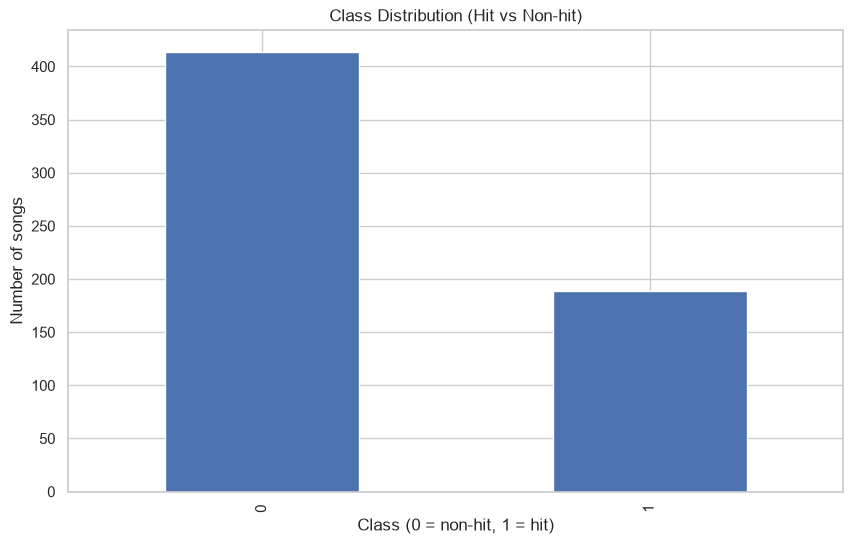

In [8]:
# Inspect class distribution to identify potential class imbalance
class_counts = df["hit"].value_counts()
class_props = df["hit"].value_counts(normalize=True)

print("Class counts:\n", class_counts)
print("\nClass proportions:\n", class_props)

plt.figure()
class_counts.plot(kind="bar")
plt.title("Class Distribution (Hit vs Non-hit)")
plt.xlabel("Class (0 = non-hit, 1 = hit)")
plt.ylabel("Number of songs")
plt.show()



Before training models, I check how balanced the target variable is.  
This matters because class imbalance can bias accuracy-based evaluations and can affect model training.

**Result:** The dataset is moderately imbalanced:  
- Non-hit (0): 414 songs (≈ 68.7%)  
- Hit (1): 189 songs (≈ 31.3%)

Because of this imbalance, I later use evaluation metrics that work well for imbalanced classification (ROC-AUC and F1).


### Numerical Feature Overview and Distributions

,bpm,nrgy,dnce,db,live,val,dur,acous,spch,pop
count,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000
mean,118.545605,70.504146,64.379768,-5.578773,17.774461,52.225539,224.674959,14.326700,8.358209,66.520730
std,24.795358,16.310664,13.378718,2.798020,13.102543,22.513020,34.130059,20.766165,7.483162,14.517746
min,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,134.000000,0.000000,0.000000,0.000000
25%,100.000000,61.000000,57.000000,-6.000000,9.000000,35.000000,202.000000,2.000000,4.000000,60.000000
50%,120.000000,74.000000,66.000000,-5.000000,12.000000,52.000000,221.000000,6.000000,5.000000,69.000000
75%,129.000000,82.000000,73.000000,-4.000000,24.000000,69.000000,239.500000,17.000000,9.000000,76.000000
max,206.000000,98.000000,97.000000,-2.000000,74.000000,98.000000,424.000000,99.000000,48.000000,99.000000


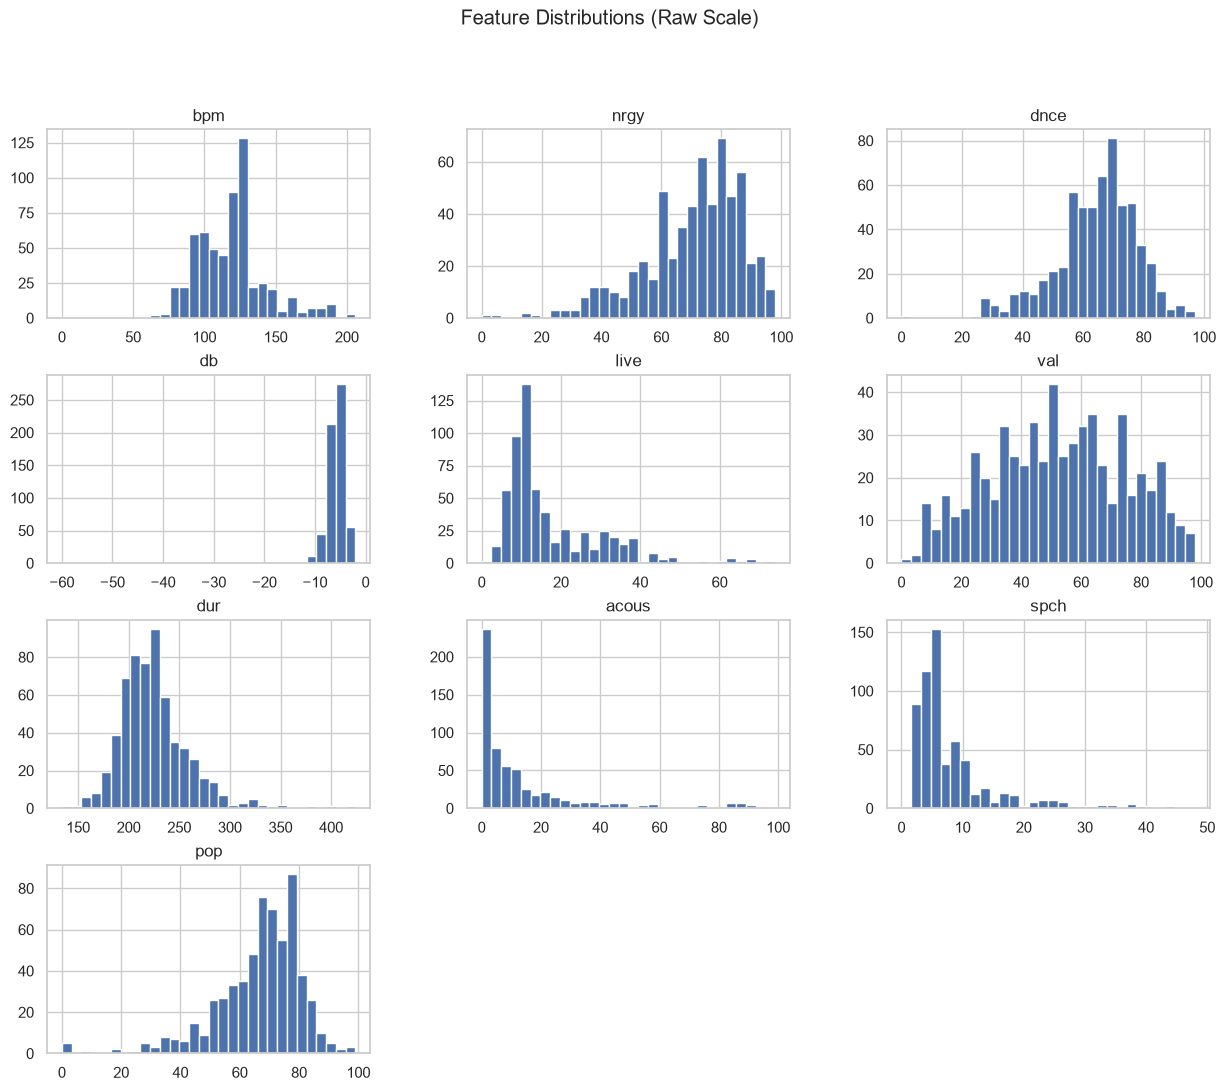

In [9]:
# Select numerical audio features
num_features = ["bpm", "nrgy", "dnce", "db", "live", "val", "dur", "acous", "spch", "pop"]

# Summary statistics
display(df[num_features].describe())

# Histograms to understand distributions
df[num_features].hist(bins=30, figsize=(15, 12))
plt.suptitle("Feature Distributions (Raw Scale)")
plt.show()




I inspect summary statistics (mean, std, min/max, quartiles) and visualize feature distributions.  
This helps detect unusual ranges, skewed features, and differences in scale that may require preprocessing.

**Result:** The audio features have different ranges and spreads (e.g., bpm vs dB vs percentage-like scores).  
This supports using feature scaling for distance-based and margin-based models (kNN, SVM).


### Pairwise Relationships Between Key Features


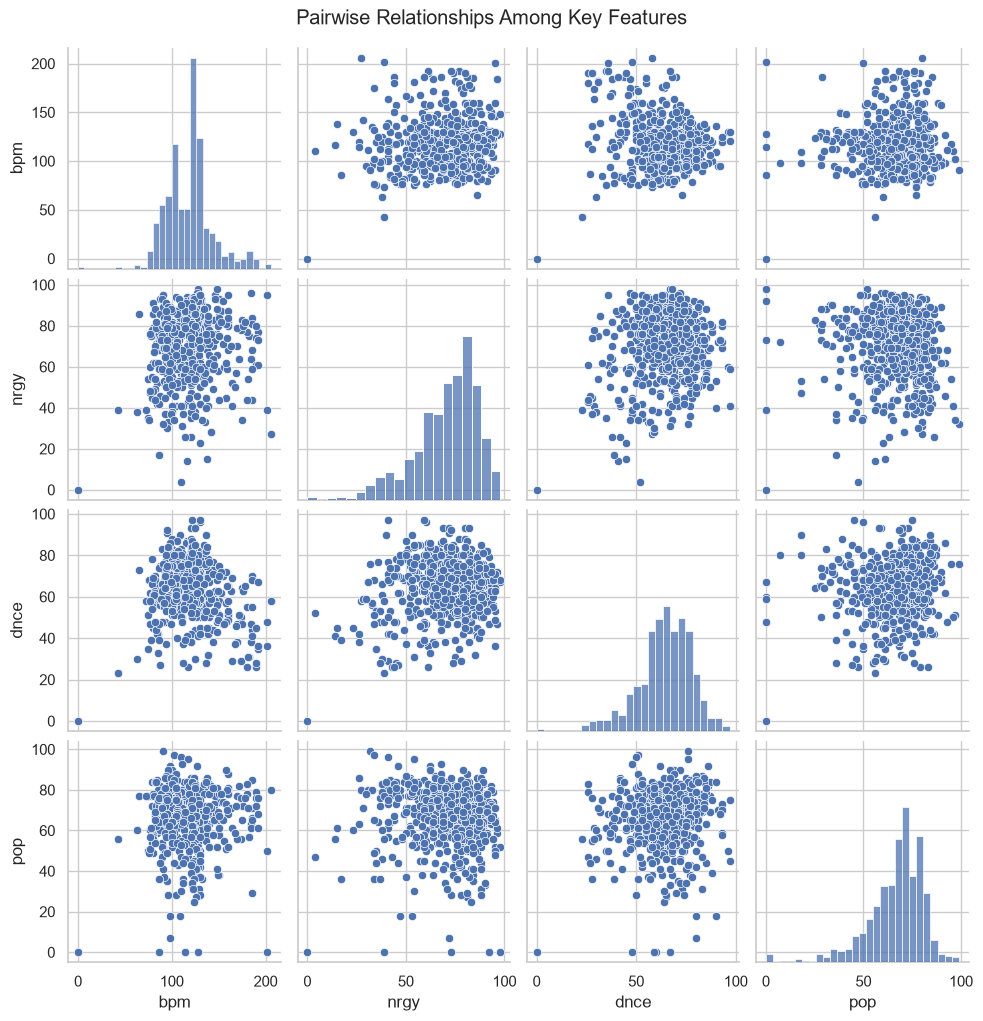

In [10]:
#Visualize pairwise relationships among selected numeric features
sns.pairplot(df[['bpm', 'nrgy', 'dnce', 'pop']])
plt.suptitle("Pairwise Relationships Among Key Features", y=1.02)
plt.show()


I visualize pairwise relationships among a small set of important numeric features (e.g., bpm, energy, danceability, popularity).  
This gives a quick impression of correlations and whether the classes might be separable in feature space.

**Result:** The relationships are not perfectly linear, and the points overlap strongly.  
This suggests the problem is non-trivial and may require flexible decision boundaries (e.g., kernel SVM).


### Correlation 

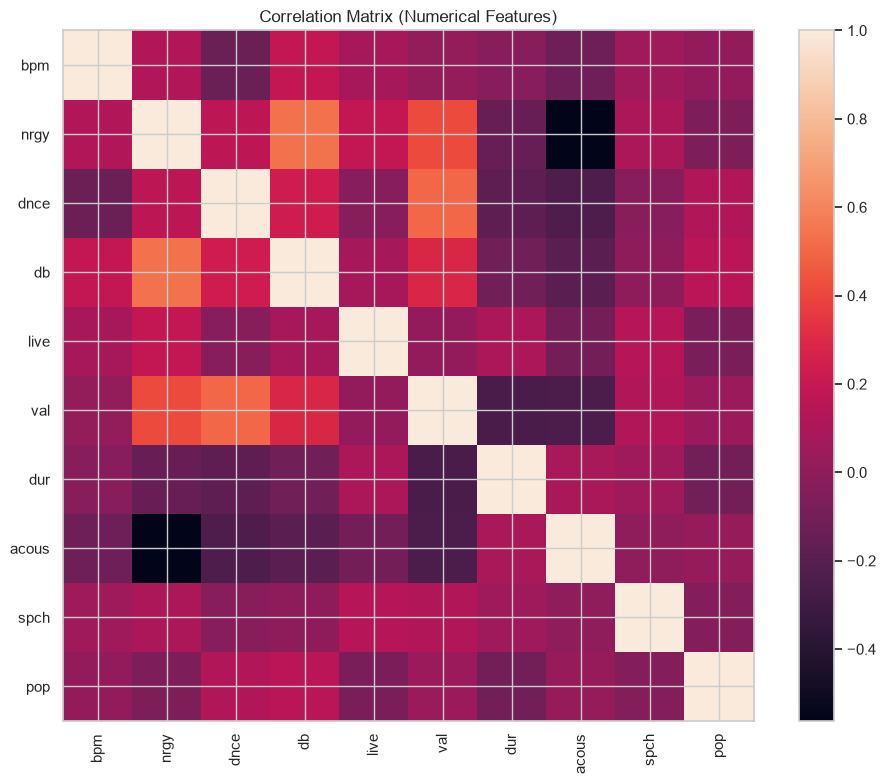

In [11]:
#  (numerical features only)
corr = df[num_features].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, interpolation="nearest")
plt.title("Correlation Matrix (Numerical Features)")
plt.colorbar()
plt.xticks(range(len(num_features)), num_features, rotation=90)
plt.yticks(range(len(num_features)), num_features)
plt.tight_layout()
plt.show()




I compute and plot a correlation matrix to identify strongly correlated features.  
Highly correlated features can be redundant and may influence model behavior.

**Result:** Some feature pairs show noticeable correlation, but there is no single feature that perfectly explains the others.  
This indicates that combining multiple audio features may be necessary for prediction.


In [12]:
# Define X and y 
# Keep top_genre as categorical
X = df.drop(columns=["title", "artist", "pop", "hit"]) 
y = df["hit"]

# Quick check
X.head(), y.head()



(         top_genre  year  bpm  nrgy  dnce  db  live  val  dur  acous  spch
 0       neo mellow  2010   97    89    67  -4     8   80  217     19     4
 1  detroit hip hop  2010   87    93    75  -5    52   64  263     24    23
 2        dance pop  2010  120    84    76  -3    29   71  200     10    14
 3        dance pop  2010  119    92    70  -4     8   71  295      0     4
 4              pop  2010  109    84    64  -5     9   43  221      2     4,
 0    1
 1    1
 2    1
 3    1
 4    1
 Name: hit, dtype: int64)

### Defining Features (X) and Target (y) – Avoiding Leakage

I define the target variable `hit` and construct the feature matrix `X`.  
To prevent data leakage, I remove identifiers (title, artist) and remove `pop` from `X` because it was used to create the target.

**Result:** The final dataset contains only song attributes that could realistically be available for prediction, and the target is stored separately as `y`.


### Summary (Task 4)

- I explored the dataset structure and checked the target distribution. The classes are moderately imbalanced (≈ 69% non-hit vs ≈ 31% hit).  
- I inspected distributions and summary statistics and observed that feature scales differ, motivating feature scaling.  
- I examined relationships and correlations between features, which suggests the problem is not trivially separable.  
- Finally, I defined `X` and `y` carefully and removed potential leakage features such as `pop` (used to build the target).


## Task 5 – First Impressions (Baseline + Two Models)

In this task, I establish a simple baseline **B** and evaluate two classification algorithms **A1** and **A2** in their default parametrization. 
I first use a single train-test split and then repeat the evaluation using a simple (non-nested) cross-validation.
All models are evaluated with the two quality criteria defined in Task 1: **ROC-AUC** and **F1-score**.

**Chosen models:**
- **B:** DummyClassifier (most frequent class)
- **A1:** k-Nearest Neighbors (kNN)
- **A2:** Support Vector Machine (SVM)

**Preprocessing considerations:**
- kNN and SVM are distance/margin-based methods and therefore require feature scaling.
- Scaling will be applied using pipelines to avoid leakage (fit on training folds only).


### Prepare the data for baseline models.


In [13]:

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import roc_auc_score, f1_score
# Drop categorical feature
X_num = X.drop(columns=["top_genre"])  # column name

# Find all non-numeric (string) columns in X
obj_cols = X.select_dtypes(include=["object"]).columns
print("Non-numeric columns:", list(obj_cols))

Non-numeric columns: ['top_genre']


**Result:** `top_genre` is the only non-numeric feature, so I drop it to use purely numeric inputs.  
I then create a stratified 80/20 train/test split to keep the class ratio similar in both sets.


### Train–Test Split

In [14]:


X_train, X_test, y_train, y_test = train_test_split(
    X_num, y, test_size=0.2, stratify=y, random_state=42)



### Define baseline models (Dummy, kNN, SVM).


In [15]:


B = DummyClassifier(strategy="most_frequent", random_state=42)

A1 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())  # default: n_neighbors=5
])

A2 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())  # default: RBF kernel, probability=False
])

models = {
    "B: Dummy (most_frequent)": B,
    "A1: kNN (default)": A1,
    "A2: SVM (default)": A2
}

pd.DataFrame({
    "Model": list(models.keys()),
    "Pipeline steps": [str(m) for m in models.values()]
})



,Model,Pipeline steps
0,B: Dummy (most_frequent),"DummyClassifier(random_state=42, strategy='mos..."
1,A1: kNN (default),"Pipeline(steps=[('scaler', StandardScaler()), ..."
2,A2: SVM (default),"Pipeline(steps=[('scaler', StandardScaler()), ..."


### Model Definitions (B, A1, A2)

- **B (Baseline):** DummyClassifier that always predicts the most frequent class.  
- **A1:** kNN (distance-based), requires feature scaling.  
- **A2:** SVM (margin-based), also benefits from feature scaling.

Scaling is applied inside pipelines to avoid data leakage.


### Evaluate models on a single train/test split.


In [16]:

def eval_train_test(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # ROC-AUC
    if hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    elif hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        # fallback
        y_score = y_pred

    return {
        "ROC-AUC (test)": roc_auc_score(y_test, y_score),
        "F1 (test)": f1_score(y_test, y_pred)
    }

train_test_results = []
for name, model in models.items():
    res = eval_train_test(model, X_train, y_train, X_test, y_test)
    res["Model"] = name
    train_test_results.append(res)

df_tt = pd.DataFrame(train_test_results).set_index("Model")
df_tt


,ROC-AUC (test),F1 (test)
Model,,
B: Dummy (most_frequent),0.500000,0.000000
A1: kNN (default),0.667406,0.540541
A2: SVM (default),0.739062,0.346154


**Result:** Dummy stays at ROC-AUC = 0.50 and F1 = 0.00.  
kNN improves clearly (ROC-AUC ≈ 0.667, F1 ≈ 0.541).  
SVM achieves the highest ROC-AUC (≈ 0.739) but a lower F1 (≈ 0.346), meaning it detects hits less often with default settings.


### Estimate performance with stratified cross-validation.


In [17]:
# Use a simple CV 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

cv_results = []
for name, model in models.items():
    scores = cross_validate(model, X_num, y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "ROC-AUC (CV mean)": scores["test_roc_auc"].mean(),
        "ROC-AUC (CV std)":  scores["test_roc_auc"].std(),
        "F1 (CV mean)":      scores["test_f1"].mean(),
        "F1 (CV std)":       scores["test_f1"].std(),
    })

df_cv = pd.DataFrame(cv_results).set_index("Model")
df_cv


,ROC-AUC (CV mean),ROC-AUC (CV std),F1 (CV mean),F1 (CV std)
Model,,,,
B: Dummy (most_frequent),0.500000,0.000000,0.000000,0.000000
A1: kNN (default),0.622561,0.030080,0.373757,0.053883
A2: SVM (default),0.661642,0.026851,0.307699,0.074598


**Result:** Cross-validation confirms the trend: SVM has the better ROC-AUC (≈ 0.662 vs ≈ 0.623 for kNN), while kNN reaches a better F1 (≈ 0.374 vs ≈ 0.308).  
All CV scores are lower than on the single test split, and the standard deviations show that results vary across folds, so CV gives a more reliable impression than a single split.


### Combine train/test and CV results for comparison.


In [18]:
# Combine train/test and CV results into one table 
df_combined = df_tt.join(df_cv, how="left")
df_combined


,ROC-AUC (test),F1 (test),ROC-AUC (CV mean),ROC-AUC (CV std),F1 (CV mean),F1 (CV std)
Model,,,,,,
B: Dummy (most_frequent),0.500000,0.000000,0.500000,0.000000,0.000000,0.000000
A1: kNN (default),0.667406,0.540541,0.622561,0.030080,0.373757,0.053883
A2: SVM (default),0.739062,0.346154,0.661642,0.026851,0.307699,0.074598


**Result:** The combined table makes it easy to compare both impressions: SVM ranks songs best (ROC-AUC), while kNN achieves higher F1 with default parameters.


### Task 5 Summary
**Result:** I compared three baseline classifiers (Dummy, kNN, SVM). The Dummy model stayed at ROC-AUC = 0.50 and F1 = 0.00, confirming a trivial baseline. Both kNN and SVM performed clearly better. SVM achieved the best ROC-AUC (strongest ranking ability), while kNN produced a higher F1-score with default settings. Cross-validation confirmed these impressions more reliably than a single train/test split and motivated hyperparameter tuning in the next task.


## Task 6 – Model Selection with Nested Cross-Validation



### Define tuning pipelines and search spaces.


In [19]:
# Pipelines (scaling + classifier)
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

# Reasonable hyperparameter grids
param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]  # 1 = Manhattan, 2 = Euclidean
}

param_grid_svm = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1],
    "svm__kernel": ["rbf"]
}




print("\nGrid sizes:")
print("kNN combinations:", len(list(ParameterGrid(param_grid_knn))))
print("SVM combinations:", len(list(ParameterGrid(param_grid_svm))))



Grid sizes:
kNN combinations: 20
SVM combinations: 16


**Result:** I create two pipelines (scaling + classifier) for kNN and SVM, and define small but reasonable hyperparameter grids.  
This keeps the experiment clear and fast while still testing meaningful settings.


### Set up nested cross-validation with GridSearchCV.


In [20]:
from sklearn.metrics import make_scorer, f1_score

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scoring = {"roc_auc": "roc_auc", "f1": "f1"}

gs_knn = GridSearchCV(
    estimator=pipe_knn,
    param_grid=param_grid_knn,
    cv=inner_cv,
    scoring="roc_auc",     # selection metric (can mention why)
    n_jobs=-1
)

gs_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    cv=inner_cv,
    scoring="roc_auc",
    n_jobs=-1
)



**Result:** I use an **outer CV** for performance estimation and an **inner CV** for hyperparameter tuning.  
Model selection inside the inner loop is based on **ROC-AUC**, and the whole process is evaluated fairly on the outer folds.


### Evaluate tuned models with nested cross-validation.


In [21]:
results = []

for name, model in [("kNN (tuned)", gs_knn), ("SVM (tuned)", gs_svm)]:
    scores = cross_validate(
        model,
        X_num, y,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1,
        return_estimator=True
    )
    results.append({
        "Model": name,
        "ROC-AUC (nested mean)": scores["test_roc_auc"].mean(),
        "ROC-AUC (nested std)":  scores["test_roc_auc"].std(),
        "F1 (nested mean)":      scores["test_f1"].mean(),
        "F1 (nested std)":       scores["test_f1"].std(),
        "estimators":            scores["estimator"]
    })

df_nested = pd.DataFrame(results).set_index("Model")
df_nested[["ROC-AUC (nested mean)", "ROC-AUC (nested std)", "F1 (nested mean)", "F1 (nested std)"]]


,ROC-AUC (nested mean),ROC-AUC (nested std),F1 (nested mean),F1 (nested std)
Model,,,,
kNN (tuned),0.678388,0.042530,0.408570,0.036896
SVM (tuned),0.666883,0.036749,0.087179,0.111590


**Result:** Nested CV performance estimates:

- **kNN (tuned):** ROC-AUC ≈ 0.678 (± 0.043), F1 ≈ 0.409 (± 0.037)  
- **SVM (tuned):** ROC-AUC ≈ 0.667 (± 0.037), F1 ≈ 0.087 (± 0.112)

Tuned kNN is slightly better on ROC-AUC and much better on F1. The tuned SVM almost never predicts the hit class at the default decision threshold, which is why its F1 collapses even though its ranking ability (ROC-AUC) is similar to kNN.


### Inspect best hyperparameters selected in each outer fold.


In [22]:
best_params = []

for model_name in df_nested.index:
    est_list = df_nested.loc[model_name, "estimators"]
    for i, est in enumerate(est_list):
        best_params.append({
            "Model": model_name,
            "Outer fold": i,
            "Best params": est.best_params_,
            "Best inner score (ROC-AUC)": est.best_score_
        })

df_best = pd.DataFrame(best_params)
df_best


,Model,Outer fold,Best params,Best inner score (ROC-AUC)
0,kNN (tuned),0,"{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__wei...",0.712572
1,kNN (tuned),1,"{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__we...",0.716897
2,kNN (tuned),2,"{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__we...",0.675948
3,kNN (tuned),3,"{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__wei...",0.652373
4,kNN (tuned),4,"{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__we...",0.696693
5,SVM (tuned),0,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.711991
6,SVM (tuned),1,"{'svm__C': 10, 'svm__gamma': 1, 'svm__kernel':...",0.675231
7,SVM (tuned),2,"{'svm__C': 0.1, 'svm__gamma': 0.01, 'svm__kern...",0.684390
8,SVM (tuned),3,"{'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel...",0.647948
9,SVM (tuned),4,"{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__k...",0.643982


**Result:** The best hyperparameters vary slightly across folds, which is expected.  
This shows that tuning depends on the training subset, and nested CV captures this variability more realistically than a single split.


### Select the final model M based on nested CV.


In [23]:
winner = df_nested["ROC-AUC (nested mean)"].idxmax()
winner


'kNN (tuned)'

**Result:** Based on the mean nested ROC-AUC, the best model is **kNN (tuned)** (ROC-AUC ≈ 0.678, F1 ≈ 0.409). It also has the clearly higher F1 (SVM: ≈ 0.087).

**Note:** Task 7 uses a fixed SVM (RBF, C = 100, gamma = 0.01) as model **M**. This choice does not follow from the nested CV result above, and this parameter combination was not selected in any outer fold. The Task 7 results therefore describe this specific SVM, not the nested-CV winner.


### Compare Task 5 impressions with Task 6 nested CV results.


In [24]:


# pick only the needed columns
t5 = df_cv[["ROC-AUC (CV mean)", "F1 (CV mean)"]].copy()
t6 = df_nested[["ROC-AUC (nested mean)", "F1 (nested mean)"]].copy()

# rename indices so they match 
rename_t5 = {
    "A1: kNN (default)": "kNN",
    "A2: SVM (default)": "SVM",
    "B: Dummy (most_frequent)": "Dummy"
}
rename_t6 = {
    "kNN (tuned)": "kNN",
    "SVM (tuned)": "SVM"
}

t5.index = t5.index.map(lambda x: rename_t5.get(x, x))
t6.index = t6.index.map(lambda x: rename_t6.get(x, x))

# combine 
compare = t5.join(t6, how="outer")

# optional: reorder rows nicely
compare = compare.loc[["Dummy", "kNN", "SVM"]]

compare



,ROC-AUC (CV mean),F1 (CV mean),ROC-AUC (nested mean),F1 (nested mean)
Model,,,,
Dummy,0.500000,0.000000,NaN,NaN
kNN,0.622561,0.373757,0.678388,0.408570
SVM,0.661642,0.307699,0.666883,0.087179


**Result:** In Task 5 (simple CV), SVM looked slightly better than kNN in ROC-AUC (≈ 0.662 vs ≈ 0.623).  
After tuning with nested CV (Task 6), kNN improves on both metrics (ROC-AUC ≈ 0.623 → 0.678, F1 ≈ 0.374 → 0.409), while the SVM stays at about the same ROC-AUC (≈ 0.662 → 0.667) and its F1 drops strongly (≈ 0.308 → 0.087).

Tuning with ROC-AUC as the selection metric therefore helped kNN, but not the SVM.


### Task 6 Summary
**Result:** I used nested cross-validation to tune and evaluate kNN and SVM fairly.  
The tuned kNN achieved the best performance (ROC-AUC ≈ 0.678, F1 ≈ 0.409); the tuned SVM reached a similar ROC-AUC (≈ 0.667) but a very low F1 (≈ 0.087).  
Compared with Task 5, tuning improved kNN, while the SVM's ROC-AUC barely changed. Overall, the achievable performance with audio features alone is moderate (ROC-AUC below 0.70 in nested CV).


# Task - 7 

## Final Model M (fixed)

In [25]:



M = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(C=100, gamma=0.01, kernel="rbf"))
])


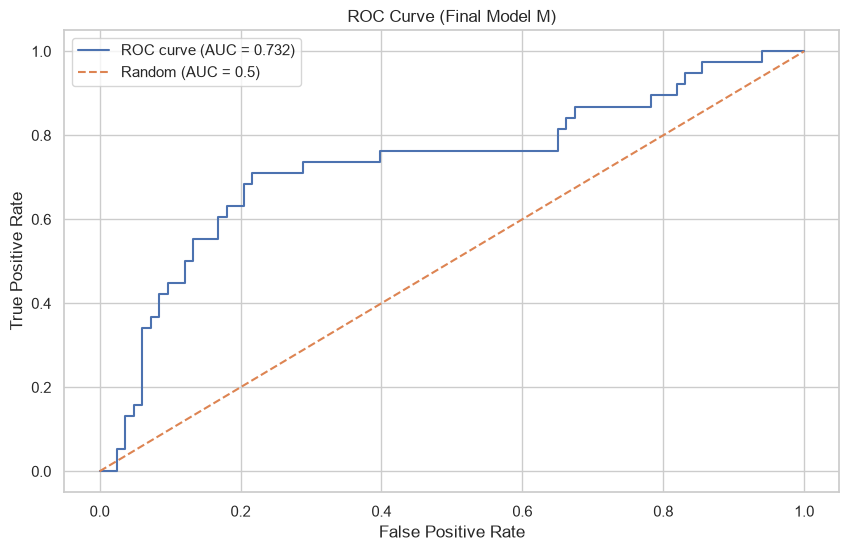

In [26]:
from sklearn.metrics import roc_curve, auc

# Fit the model first
M.fit(X_train, y_train)

# probability/score
if hasattr(M, "decision_function"):
    y_score = M.decision_function(X_test)
else:
    y_score = M.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Final Model M)")
plt.legend()
plt.show()


### Final Model M (Fixed)

In this task, I use a fixed model **M**: an RBF SVM with C = 100 and gamma = 0.01 (no further tuning). These hyperparameters were set manually and are not the result of the nested CV in Task 6 (see the note there).  
Keeping M fixed makes sure that any performance changes later come only from changing the feature set.

On the held-out test split, M reaches a ROC-AUC of 0.732 (see the ROC curve above).


### Permutation Feature Importance

I compute **permutation importance** for the final model M.  
A feature is important if shuffling it causes a clear drop in ROC-AUC on a held-out test set.


In [27]:

from sklearn.inspection import permutation_importance

X_train, X_test, y_train, y_test = train_test_split(
    X_num, y, test_size=0.2, stratify=y, random_state=42
)

M.fit(X_train, y_train)

perm = permutation_importance(
    M, X_test, y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    "feature": X_num.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)


imp_df


,feature,importance_mean,importance_std
0,year,0.159713,0.051950
2,nrgy,0.037138,0.018119
8,acous,0.018537,0.012324
1,bpm,0.016371,0.015936
3,dnce,0.012429,0.014685
7,dur,0.005041,0.019909
6,val,0.002378,0.011483
5,live,-0.001955,0.007520
4,db,-0.005982,0.007988
9,spch,-0.010812,0.011054


**Result:** The most important feature is **year** (largest decrease in ROC-AUC when shuffled).  
Other relevant features include **nrgy** and **acous**, while some features show near-zero or negative importance.


### Visualization of Feature Importance

I plot the permutation importances to clearly compare the relative contribution of each feature.  
This diagram helps identify both the strongest drivers and the weakest (potentially noisy) features.


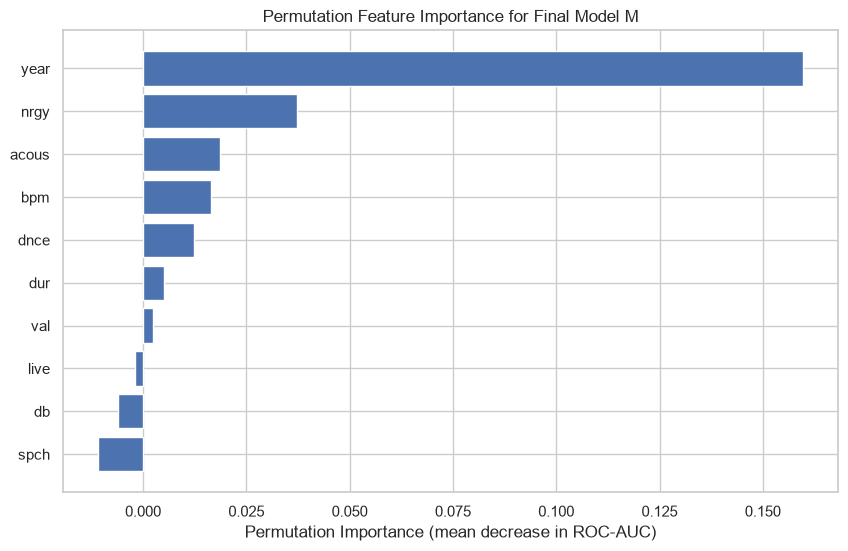

In [28]:


plt.figure(figsize=(10, 6))
plt.barh(imp_df["feature"], imp_df["importance_mean"])
plt.gca().invert_yaxis()
plt.xlabel("Permutation Importance (mean decrease in ROC-AUC)")
plt.title("Permutation Feature Importance for Final Model M")
plt.show()


**Result:** The plot confirms that **year** dominates the model’s performance.  
At the bottom, **spch** and **db** have the lowest (even slightly negative) importance, suggesting they provide little useful signal for this model.


### Selecting the Two Least Important Features (F1 and F2)

Based on the permutation importance results, I select the two least important features for the ablation study.


In [29]:
least_2 = imp_df.sort_values("importance_mean", ascending=True).head(2)["feature"].tolist()
F1, F2 = least_2[0], least_2[1]
F1, F2


('spch', 'db')

**Chosen features:**  
- **F1 = spch**  
- **F2 = db**


### Pipeline with Feature Removal Step

To remove features correctly inside cross-validation, I implement feature dropping as a **preprocessing step inside the pipeline**.  
This prevents leakage and ensures the same training procedure across all folds.


In [30]:
from sklearn.preprocessing import FunctionTransformer


def make_M_with_drop(drop_cols):
    dropper = FunctionTransformer(
        lambda X: X.drop(columns=drop_cols, errors="ignore"),
        validate=False
    )
    return Pipeline([
        ("drop", dropper),
        ("scaler", StandardScaler()),
        ("svm", SVC(C=100, gamma=0.01, kernel="rbf"))
    ])


### Ablation Study

I evaluate the same model M under four settings:
1) all features (reference),
2) without F1,
3) without F2,
4) without both F1 and F2.

The evaluation uses `cross_validate` with scikit-learn's default 5-fold stratified CV (without shuffling). Note that the outer CV splits from Task 6 are not passed in here, so the folds differ from Task 6.

No hyperparameter optimization is performed here.


In [31]:
configs = {
    "M (all features)": [],
    f"M (-{F1})": [F1],
    f"M (-{F2})": [F2],
    f"M (-{F1}, -{F2})": [F1, F2]
}

rows = []
for label, drops in configs.items():
    model = make_M_with_drop(drops)
    scores = cross_validate(
        model, X_num, y,
        scoring=scoring,
        n_jobs=-1
    )
    rows.append({
        "Setting": label,
        "ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "ROC-AUC (std)": scores["test_roc_auc"].std(),
        "F1 (mean)": scores["test_f1"].mean(),
        "F1 (std)": scores["test_f1"].std(),
    })

df_ablation = pd.DataFrame(rows).set_index("Setting")
df_ablation


,ROC-AUC (mean),ROC-AUC (std),F1 (mean),F1 (std)
Setting,,,,
M (all features),0.668857,0.163134,0.247527,0.197394
M (-spch),0.687765,0.142181,0.239171,0.208669
M (-db),0.674792,0.182433,0.265459,0.176949
"M (-spch, -db)",0.686377,0.154559,0.231328,0.203443


### Ablation Results

The table below reports mean ± standard deviation across CV folds for ROC-AUC and F1-score.  
I compare these results to the feature importance ranking.


**Result interpretation:**
- Removing **spch** increases ROC-AUC (0.669 → 0.688) and slightly reduces F1 (0.248 → 0.239).
- Removing **db** slightly increases ROC-AUC (0.669 → 0.675) and F1 (0.248 → 0.265).
- Removing **both spch and db** gives ROC-AUC ≈ 0.686 and F1 ≈ 0.231.

All changes are small compared to the standard deviations across folds (ROC-AUC std ≈ 0.14–0.18, F1 std ≈ 0.18–0.21), which suggests that these features have limited impact — consistent with their low permutation importance.


### Summary (Task 7)

- I computed permutation feature importance for the fixed model M and visualized the results.
- The most influential feature is **year**, followed by features like **nrgy** and **acous**.
- The two least important features are **spch (F1)** and **db (F2)**.
- In the ablation study (5-fold CV), removing F1/F2 caused only small performance changes, which supports the feature importance impression that these features contribute little to the model.


## Task 8 – Conclusions and Future Work


### 1) Conclusions 

**Result:** In Task 1, the goal was to support **Gbedu Music** with an early, data-driven way to estimate whether a new song is likely to become a **hit** using only audio characteristics.  
The trained models perform better than a trivial baseline (Dummy), which shows that audio features contain some useful signal for predicting hit vs non-hit. However, the signal is moderate: in nested cross-validation, the best model reached a ROC-AUC of only about 0.68.

The best approach in nested CV was the tuned **kNN** (ROC-AUC ≈ 0.678, F1 ≈ 0.409). The tuned SVM ranked songs about as well (ROC-AUC ≈ 0.667) but detected very few hits at the default threshold (F1 ≈ 0.087).

In Task 7, permutation importance for the fixed SVM showed that **year** is the most influential feature, while **spch** and **dB** contribute very little. The ablation study confirmed this impression: removing these weak features changes performance only slightly, which suggests they add limited value for the model.


### 2) Value for the Customer (Gbedu Music)

**Result:** The main value is an **early screening tool**. Before releasing a song, Gbedu Music can feed the song’s audio features into the model and obtain a **hit-likelihood estimate**.  
This supports better decisions such as:
- prioritizing songs with higher predicted hit chance for marketing and playlist pitching,
- reducing wasted promotion budget on low-probability songs,
- identifying which audio characteristics seem most connected to successful songs.

### 3) Future Work (Project-specific)

- **Handle the strong “year” effect:** Train and evaluate an additional version **without `year`**, or use **time-based evaluation** (train on earlier years, test on later years) to check if the model generalizes across changing music trends.
- **Include genre properly:** Instead of dropping `top_genre`, encode it (e.g., one-hot encoding in the pipeline) and test whether it improves hit detection, because genres often have different typical audio profiles.
- **Calibrate decision thresholds:** Choose a threshold based on business needs (e.g., “we prefer not to miss hits”), and optionally apply probability calibration so predictions are more reliable for decision-making.

### 4) Critical Reflection (Limitations and Usability)

- **Definition of “hit”:** The target is based on a popularity threshold, which is a simplified definition of success and may not reflect all real-world factors.
- **Missing external drivers:** True success also depends on marketing, artist fame, and social media, which are not in the dataset. Therefore, the model cannot be perfect.
- **Time dependency:** Because `year` is very influential, the model may partially learn “era trends” rather than pure audio quality. This should be handled carefully for real deployment.

Overall, the methodology is useful as a **decision-support tool** for early filtering and prioritization, but it should be combined with human judgment and, ideally, additional non-audio information in a real business setting.